In [ ]:
# the first cell provides metadata (raw cell)

# Rocket Equation
At time $t_0$ to rocket starts to expel gas at a
_constant mass flow rate_ $R$ meassured in kg/s
and _exhaust velocity relative to the rocket_
$v_e$ in m/s.
$$
\frac{dv}{dt} = -\frac{F}{m(t)} = -\frac{Rv_e}{m(t)}
$$

In [ ]:
# in between the $$ in Markdown, there is a maths-term
# backslash frac gives a fraction

# Notes Session 6

In [1]:
def sum_prod(a,b,c=1):
    return c*(a+b)

In [3]:
sum_prod(c=1, a=2, b=2)

4

In [4]:
name="Kira"
age="28"

In [6]:
print (name, age, sep=" is ")

Kira is 28


# Reading a Data file and plotting
*Copy from session 4 to use for session 6*

## Import needed files

In [17]:
import numpy # import needed files first
from matplotlib import pyplot #import from matplotlib the function for this code

## Open the files and read it, so it is usable

In [18]:
# input = name of the file, output = time and absorption
# now this cell is a function in itself
def read_pulse (fname):
    dataFile = open(fname)
    time= []
    absorption=[]
    dataFile.readline()
    for line in dataFile.readlines() :
        line=line.split(",")
        time.append(float(line[0]))
        absorption.append(float(line[1]))
    return time, absorption

In [19]:
time, absorption =read_pulse ("../data/pulse_data.csv") # call the function and open the according dataset, so it can run

## Basic Plot

Text(0.5, 0, 'time [s]')

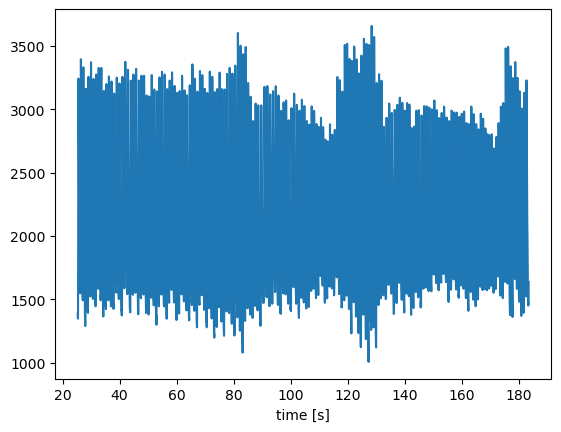

In [20]:
#| label: fig-dataset
#| fig-cap: "Measurements from an oxymetry sensor as a
#| function of time for 3 cycles"
pyplot.plot(time, absorption)
pyplot.xlabel("time [s]")

# Python Arrays

In [ ]:
a=numpy.arange(10)+1

In [ ]:
a.shape

In [ ]:
a.dtype

In [ ]:
a.nbytes

In [ ]:
b=numpy.array([[1,2,3],[4,5,6]])

In [ ]:
b.shape

In [ ]:
b.T @ b

In [ ]:
a.T@ a # @= Vektorprodukt

In [ ]:
a

In [ ]:
numpy.max(a) # tells the biggest number

In [ ]:
numpy.argmax(a) # tells the maximum position (starting at 0)

## Calculate pulse rate

$$H = \frac{T}{\Delta T_{\text{peaks}}}$$

In [ ]:
absorption = numpy.array(absorption)
time = numpy.array(time)

In [ ]:
w=50 # w = window (compare a point to the points around)

In [ ]:
subset = absorption # now the subset is the whole data set. to practice you can e.g. choose the subset until 1000

In [ ]:
peaks = []
for i in range (len(subset)): # the window moves along the dataset
    start = max(i-w, 0) # the point before is lower (i-w), 0 to include start of data
    end = min(i+w, len(subset)) # len(subset) to include the end of data
    window = subset[start:end]
    max_pos = numpy.argmax(window) + start # gives us the position inside the window, where the maximum is
    if i == max_pos:
        peaks.append(i)
print(peaks)

In [ ]:
pyplot.plot(subset)
pyplot.plot(peaks, subset[peaks], "ro")

In [ ]:
time_peaks = time[peaks]

In [ ]:
delta_t = time_peaks[1:] -time_peaks[:-1]

In [ ]:
hr = 60/ delta_t

In [ ]:
pyplot.plot(hr)

### Connotations

#### Graph with peaks

In [ ]:
test = numpy.arange(20)

In [ ]:
test

In [ ]:
s= test[5:10] # create a subset

In [ ]:
s

=> the index of numbers in our window does change and not match the index in the whole array, so we need to add the lower bound of our subset (+ start in max_pos above)

#### Graph heart rate

In [ ]:
peaks # to get a list of peaks

In [ ]:
time[peaks] #create an array of time

In [ ]:
tp=time[peaks]

In [ ]:
tp[1:]-tp[:-1] # = delta t